# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [112]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [113]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [114]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


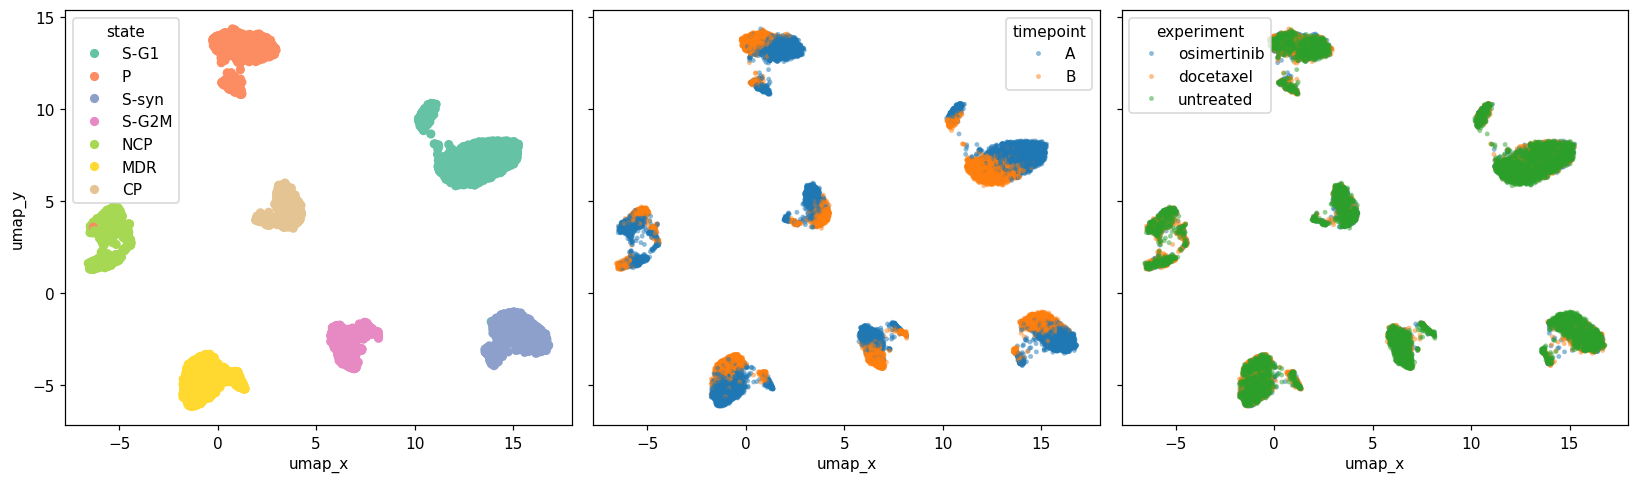

In [115]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [116]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [117]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [119]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [120]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [121]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [122]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

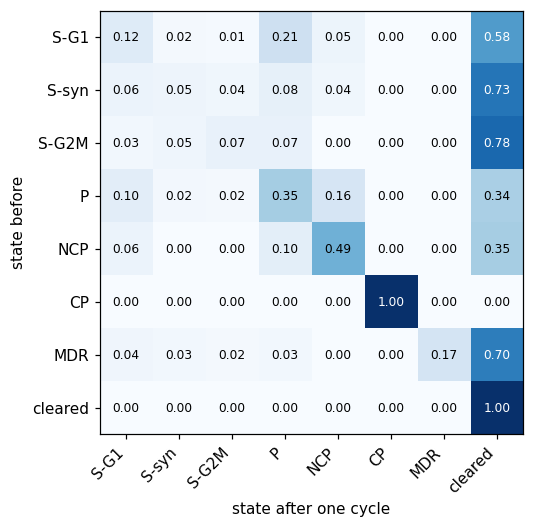

In [123]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

*Answer here.*
CP seems to also be absorbing under osimertinib. This means that cells that are in state CP does not respond to the drug treatment and is resistant, meaning one needs to find another way to fight those cells in that state. 

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

** Prediction **

I predict S-G1, S-syn, S-G2M, P, NCP, and MDR can be eliminated completely because it can become different cell states and has a path to cleared and can evenitally die. However, CP cannot be eliminated completely because the only state the cell can transition to is CP. No other cell has any probability to transition to CP. 

In [124]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [125]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [126]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


** Result **
No we do not, the cleared rate is 0.989 meaning 0.011 of the cancer cells still lives. The cells that remain are in the following categories: S-G1, P, and NCP.

The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

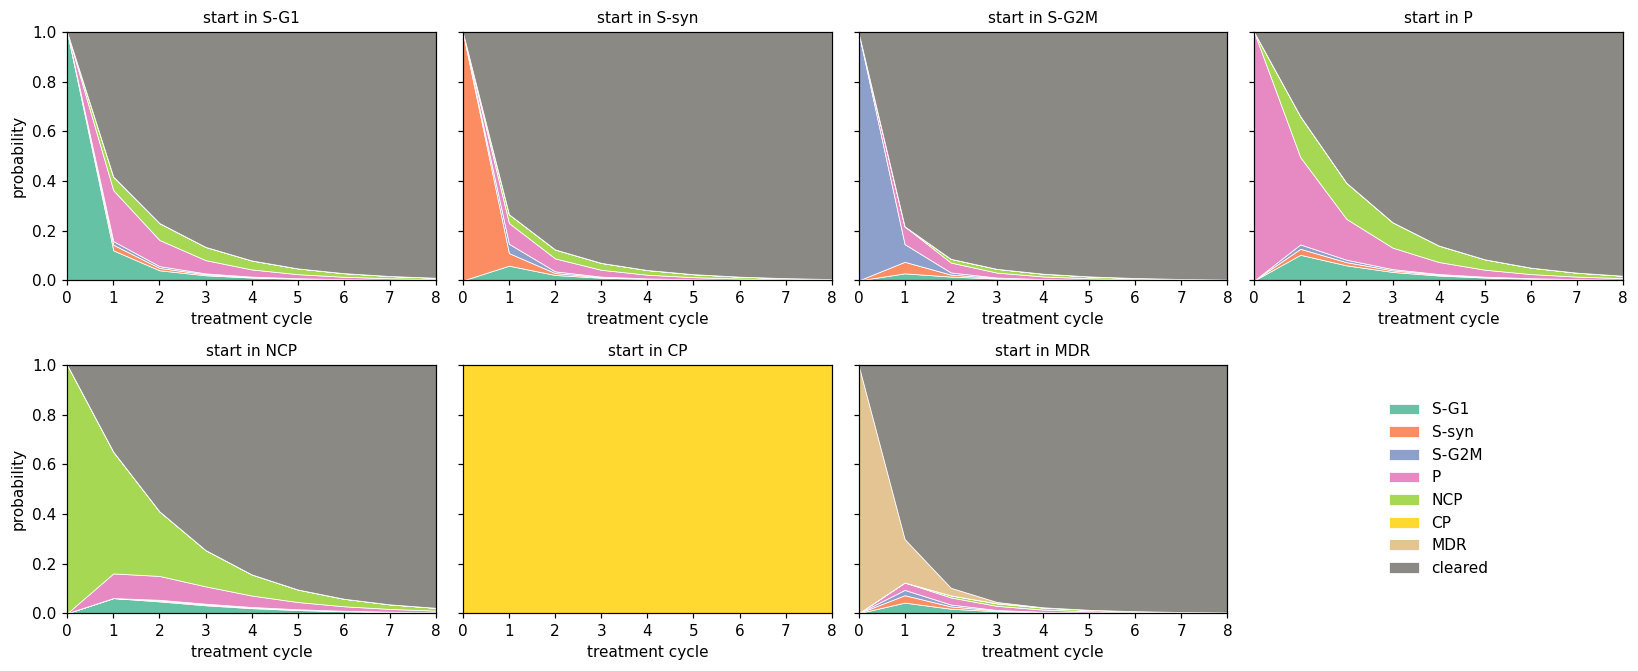

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [127]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive4 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive4.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



1. Shown by the output of the code below as well as the graphs above, starting states with S-syn, S-G2M, and MDR were (mostly) completely eliminated by osimertinib. Starting states with S-G1, P, NCP, and CP survived. 
2. S-syn lasted the longest looking at the fraction alive after 4 cycles (S-syn had the highest value out of the three)
3. CP did not change at all and survived entirely. Other than CP, the one with starting state NCP lasted the longest. 
4. CP. If we excluded CP, NCP starting state results in the highest proportion of alive cells after three cycles. 

In [128]:
# To help answer above question 
alive8 = {s: 1 - evolve(basis(s, P_hat), P_hat, 8)[-1, -1] for s in OUTCOMES}
for s,v in alive8.items():
    print("fraction alive after 8 cycles, starting in", s, ":", round(v, 3))

fraction alive after 8 cycles, starting in S-G1 : 0.011
fraction alive after 8 cycles, starting in S-syn : 0.006
fraction alive after 8 cycles, starting in S-G2M : 0.004
fraction alive after 8 cycles, starting in P : 0.019
fraction alive after 8 cycles, starting in NCP : 0.022
fraction alive after 8 cycles, starting in CP : 1.0
fraction alive after 8 cycles, starting in MDR : 0.003
fraction alive after 8 cycles, starting in cleared : 0.0


In [129]:
# To help answer above question 
alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 3)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 3 cycles, starting in", s, ":", round(v, 3))

fraction alive after 3 cycles, starting in S-G1 : 0.135
fraction alive after 3 cycles, starting in S-syn : 0.071
fraction alive after 3 cycles, starting in S-G2M : 0.047
fraction alive after 3 cycles, starting in P : 0.234
fraction alive after 3 cycles, starting in NCP : 0.254
fraction alive after 3 cycles, starting in CP : 1.0
fraction alive after 3 cycles, starting in MDR : 0.045
fraction alive after 3 cycles, starting in cleared : 0.0


### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

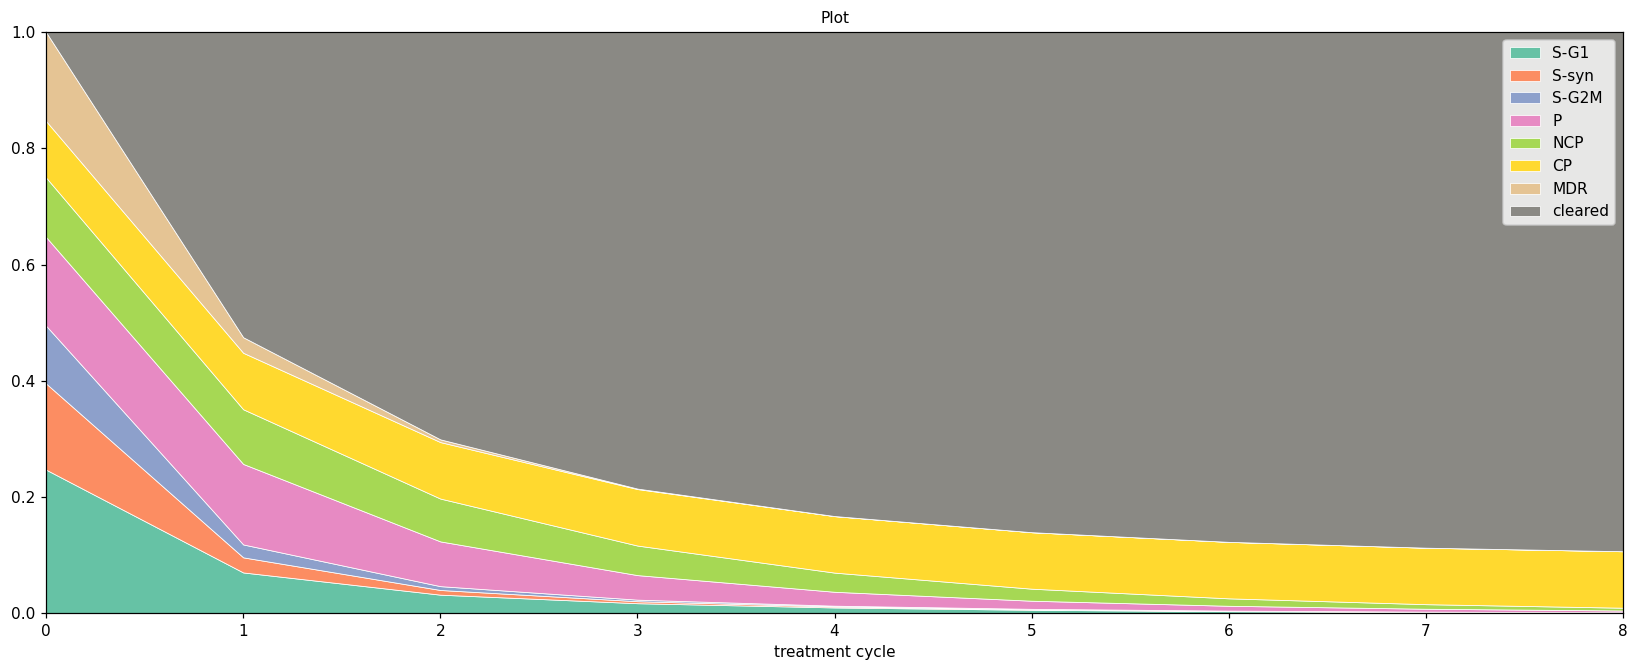

In [ ]:
# Your code here
# TODO: set this equal to the starting vector from timepoint A
at_A = cells[cells.timepoint == "A"]['state'].value_counts(normalize=True)
pi_mix = at_A.reindex(P_hat.columns,fill_value=0).to_numpy()  


# evolve pi_mix and plot the results
traj = evolve(pi_mix, P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

fig, axes = plt.subplots(figsize=(15, 6.2))
plot_trajectory(traj, axes, "Plot")
axes.legend()
plt.tight_layout()
plt.show()

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

CP ends up dominating the remaining cluster. No these cells will never be cleared as we saw in the matrix that cells that are in CP are trapped in CP. In the long-run, all the cells end up in the states that once they are in, they cannot leave (CP and cleared), what we earlier said are absorbing under osimertinib. 

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [ ]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat.to_numpy()


doc = cells[cells["experiment"] == "docetaxel"]
at_A = doc[doc.timepoint == "A"][["lineage_tag", "state"]]
at_B = doc[doc.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))


P_doc = counts.div(counts.sum(axis=1), axis=0) # TODO
assert np.allclose(P_doc.sum(axis=1), 1), "Every row should sum to 1."
P_doc.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_doc.columns})
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]



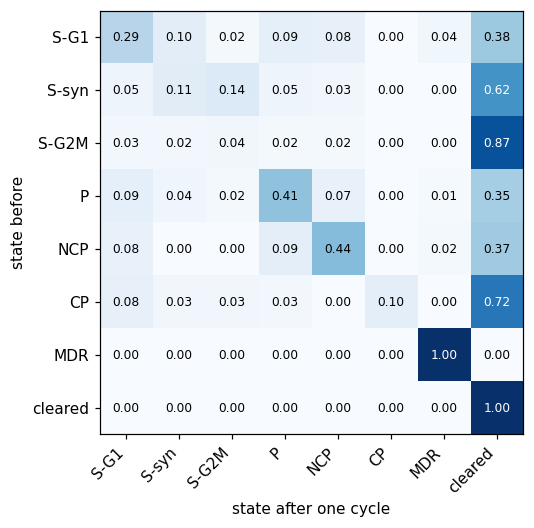

In [132]:
#Plot the transition matrices for docetaxel and the drug holiday.
show_matrix(P_doc)

In [133]:
untreated = cells[cells["experiment"] == "untreated"]
at_A = untreated[untreated.timepoint == "A"][["lineage_tag", "state"]]
at_B = untreated[untreated.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))

P_holiday = counts.div(counts.sum(axis=1), axis=0) # TODO
assert np.allclose(P_holiday.sum(axis=1), 1), "Every row should sum to 1."
P_holiday.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_holiday.columns})
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

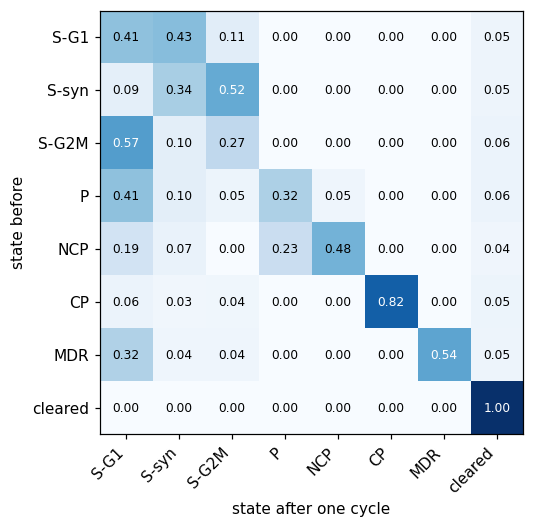

In [134]:
show_matrix(P_holiday)

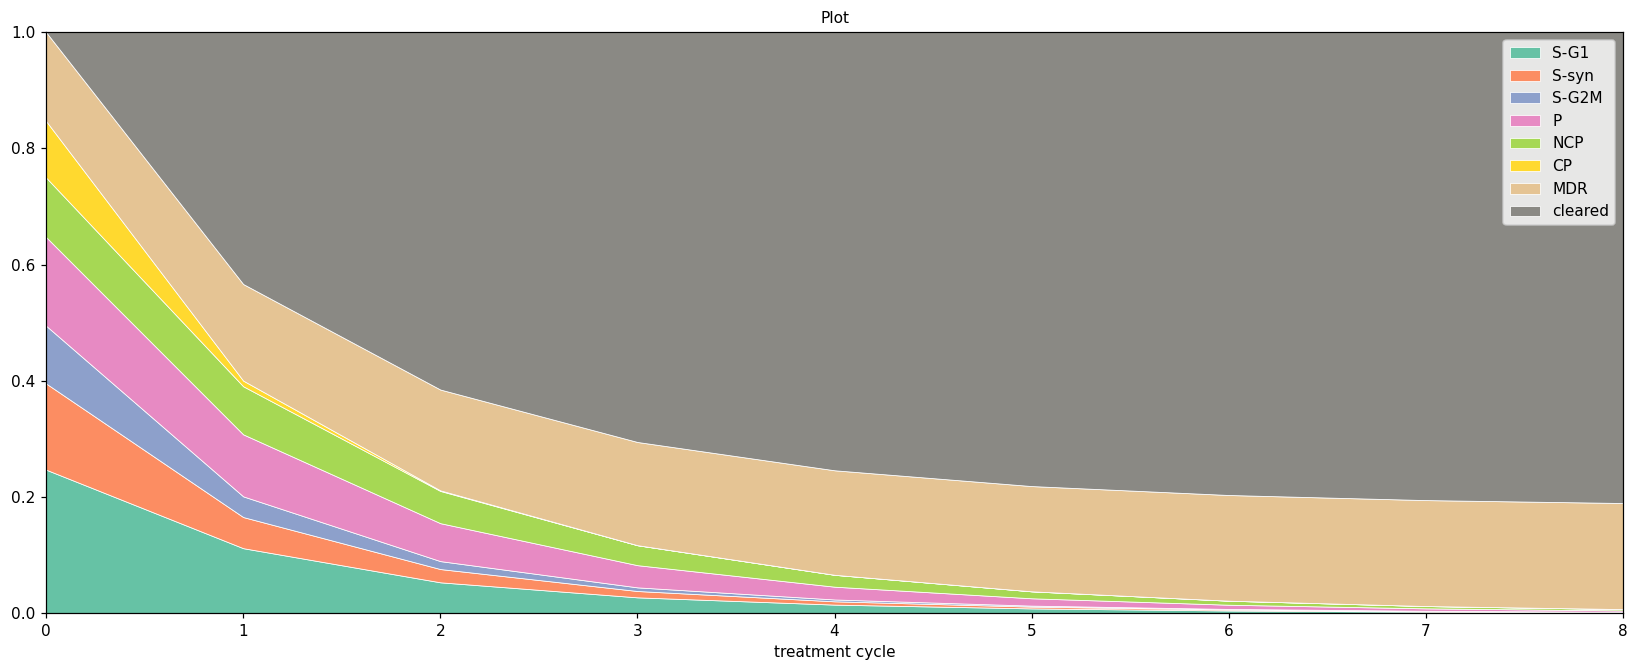

In [135]:
# Simulate the evolution of pi_mix under docetaxel 
at_A = cells[cells.timepoint == "A"]['state'].value_counts(normalize=True)
pi_mix = at_A.reindex(P_doc.columns,fill_value=0).to_numpy()  
# TODO: set this equal to the starting vector from timepoint A

# evolve pi_mix and plot the results
traj = evolve(pi_mix, P_doc, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

fig, axes = plt.subplots(figsize=(15, 6.2))
plot_trajectory(traj, axes, "Plot")
axes.legend()
plt.tight_layout()
plt.show()

*Answer questions in markdown here.*

1. Compared to osimertinib, CP no longer is an absorbing state for either of them. Drug Holiday's state after one cycle for the cleared column is low comapred to the other two matrix. For docetaxel cleared and MDR are absorbing states. For the drug holiday, only cleared is an absorbing state. 

2. Instead of cleared and CP dominating towards the later cycles, it is MDR and cleared. 

## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [136]:
#1
P_osi_np = P_hat.to_numpy()
traj = evolve(pi_mix,P_osi_np,8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


In [137]:
#1
P_doc_np = P_doc.to_numpy()
traj = evolve(pi_mix,P_doc_np,8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


In [ ]:
#1
P_osi_doc = P_osi_np @ P_doc_np 
traj = evolve(pi_mix,P_osi_doc,4)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.050,0.019,0.012,0.076,0.058,0.010,0.033,0.741
2,0.015,0.005,0.003,0.026,0.025,0.001,0.008,0.918
3,0.005,0.002,0.001,0.009,0.009,0.000,0.002,0.973
4,0.002,0.001,0.000,0.003,0.003,0.000,0.001,0.991


In [139]:
#2
P_doc_osi = P_doc_np @ P_osi_np 
traj = evolve(pi_mix,P_doc_osi,4)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.041,0.014,0.012,0.081,0.066,0.010,0.029,0.747
2,0.012,0.003,0.003,0.027,0.028,0.001,0.006,0.920
3,0.004,0.001,0.001,0.009,0.011,0.000,0.001,0.973
4,0.001,0.000,0.000,0.003,0.004,0.000,0.000,0.991


*Answer questions here.*

1. The alternating schedule seems to be more effective, increasing the proportion of cells cleared compared to just one treatment alone. 

2. It does not seem to make a siginifcant difference if you start with osimertinib first or docetaxel first for this particular tumor. 

3. Drug holidays seem to help clear the tumor if one has a lot of cells that either one of the treatments are resistant to, by combining the reisisted treatment and the drug holiday. This may be critical if a patient is allergic to the treatment that the cells are not resistant to (making the more effective treatment not usable). Additionally it is successful when there are a even proportion of the various cells (alternating between treatment and drug holiday). 

4. Treatment Plan: 
The following treatment plans assume one would go through 8 rounds of therapy (unless otherwise speciied). 

I created treatment plans for patient with mix/even proportion of the various cells, one with all drug tolerant persisters, all resistant cells, and majority resistant cells. 


Situation: Mix/Even proportion of starting cells 
Treatment Strategy: Alternating between docetaxel, osimeritinib, and drug holiday (as that had the highest cleared rate at round 8) 

Situation: All drug tolerant persisters (all the starting cells are CP)
Treatment Strategy: Highest percent cleared was alternating between the two treatments, however if the patient prefers to go through less rounds of therapy alternating between docetaxel and drug holiday cleared more than 0.9 indicating effectiveness. 

Situation: All resistant cells (all the starting cells are MDR) and Majority resistant cells
Treatment Strategy: Treating it with the treatment that the cells are not resistant to as in this case, treating with osimeritinib, it cleared 99.9% of the cells. If the patient cannot have the respective treatment, alternating between drug holiday and the resistant treatment proved to be effective as the alternate one has cleared rate of 0.759 compared to 0.284 when it was majority resistant and only the resisted drug was used. 


In [ ]:
P_holiday_np = P_holiday.to_numpy()

even = {'S-G1':0.14,
        'S-syn':0.14,
        'S-G2M':0.14,
        'P':0.14,
        'NCP':0.14,
        'CP':0.14,
        'MDR':0.16
        }

all_persisters = {'S-G1':0,
        'S-syn':0,
        'S-G2M':0,
        'P':0.5,
        'NCP':0.5,
        'CP':0,
        'MDR':0  
}


majority_resistant = {'S-G1':0,
        'S-syn':0,
        'S-G2M':0,
        'P':0.3,
        'NCP':0,
        'CP':0,
        'MDR':0.7  
}

pi_persisters = (pd.Series(all_persisters).reindex(P_hat.columns,fill_value=0).to_numpy())
pi_majority_resistant = (pd.Series(majority_resistant).reindex(P_hat.columns,fill_value=0).to_numpy())
pi_even = (pd.Series(even).reindex(P_hat.columns,fill_value=0).to_numpy())

** Testing for mix/even ** 

In [ ]:
traj = evolve(pi_even,P_doc_osi,4)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.140,0.140,0.140,0.140,0.140,0.140,0.160,0.000
1,0.171,0.079,0.055,0.052,0.047,0.011,0.092,0.491
2,0.099,0.052,0.034,0.025,0.022,0.001,0.054,0.712
3,0.056,0.029,0.020,0.013,0.012,0.000,0.032,0.838
4,0.032,0.017,0.011,0.007,0.006,0.000,0.019,0.909


In [225]:
P_doc_np = P_doc.to_numpy()
traj = evolve(pi_mix,P_doc_np,7)
traj1 = evolve(traj[-1],P_holiday_np,1)
pd.DataFrame(traj1, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.003,0.001,0.001,0.004,0.004,0.0,0.182,0.805
1,0.062,0.010,0.009,0.002,0.002,0.0,0.099,0.815


In [226]:
P_osi_np = P_hat.to_numpy()
P_doc_np = P_doc.to_numpy()
P_holiday_np = P_holiday.to_numpy()

P_doc_osi = P_doc_np @ P_osi_np 
traj = evolve(pi_mix,P_doc_osi,2)
traj1 = evolve(traj[-1],P_holiday_np,2)
traj2 = evolve(traj1[-1],P_doc_osi,1)
pd.DataFrame(traj2, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.025,0.018,0.011,0.008,0.008,0.001,0.002,0.928
1,0.003,0.001,0.001,0.006,0.005,0.000,0.001,0.983


In [191]:
traj = evolve(pi_even, P_doc_osi, 1)
traj1 = evolve(traj[-1],P_holiday_np,1)
traj2 = evolve(traj1[-1],P_doc_osi,1)
traj3 = evolve(traj2[-1],P_holiday_np,1)
traj4 = evolve(traj3[-1],P_doc_osi,1)
pd.DataFrame(traj4, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.020,0.009,0.005,0.011,0.010,0.001,0.002,0.942
1,0.003,0.001,0.001,0.006,0.005,0.000,0.001,0.984


In [227]:
traj = evolve(pi_mix, P_doc, 3)
traj1 = evolve(traj[-1],P_holiday_np,2)
traj2 = evolve(traj1[-1],P_doc,3)
pd.DataFrame(traj2, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.096,0.061,0.036,0.011,0.010,0.0,0.052,0.735
1,0.034,0.018,0.012,0.018,0.015,0.0,0.056,0.847
2,0.014,0.006,0.004,0.013,0.012,0.0,0.058,0.893
3,0.007,0.003,0.002,0.008,0.007,0.0,0.059,0.915


In [193]:
traj = evolve(pi_mix, P_doc, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


In [218]:
P_doc_holiday = P_holiday_np @ P_doc_np
traj = evolve(pi_mix, P_doc_holiday, 4)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.122,0.063,0.043,0.078,0.064,0.008,0.096,0.525
2,0.059,0.030,0.020,0.040,0.035,0.001,0.059,0.756
3,0.030,0.015,0.010,0.021,0.018,0.000,0.036,0.870
4,0.016,0.008,0.005,0.011,0.010,0.000,0.021,0.930


** All resistant **

In [220]:
traj = evolve(basis('MDR',P_hat), P_osi, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.000,0.000,0.000,0.000,0.000,0.0,1.000,0.000
1,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701
2,0.018,0.009,0.008,0.028,0.008,0.0,0.031,0.898
3,0.008,0.003,0.002,0.017,0.010,0.0,0.005,0.955
4,0.004,0.001,0.001,0.009,0.008,0.0,0.001,0.976
5,0.002,0.000,0.000,0.005,0.006,0.0,0.000,0.986
6,0.001,0.000,0.000,0.003,0.004,0.0,0.000,0.992
7,0.001,0.000,0.000,0.002,0.002,0.0,0.000,0.995
8,0.000,0.000,0.000,0.001,0.001,0.0,0.000,0.997


In [221]:
traj = evolve(basis('MDR',P_hat), P_doc_holiday, 4)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.000,0.000,0.000,0.000,0.000,0.0,1.000,0.000
1,0.097,0.039,0.014,0.032,0.028,0.0,0.553,0.237
2,0.081,0.037,0.019,0.036,0.032,0.0,0.309,0.485
3,0.057,0.027,0.015,0.029,0.026,0.0,0.174,0.673
4,0.037,0.018,0.010,0.020,0.018,0.0,0.099,0.798


** All Persisters ** 

In [206]:
traj = evolve(pi_persisters, P_doc, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.000,0.000,0.000,0.500,0.500,0.0,0.000,0.000
1,0.083,0.020,0.012,0.251,0.255,0.0,0.018,0.361
2,0.067,0.021,0.011,0.136,0.137,0.0,0.031,0.598
3,0.044,0.015,0.008,0.076,0.076,0.0,0.038,0.744
4,0.026,0.009,0.005,0.043,0.043,0.0,0.042,0.831
5,0.015,0.006,0.003,0.025,0.024,0.0,0.045,0.882
6,0.009,0.003,0.002,0.014,0.014,0.0,0.046,0.912
7,0.005,0.002,0.001,0.008,0.008,0.0,0.047,0.929
8,0.003,0.001,0.001,0.005,0.005,0.0,0.047,0.939


In [207]:
traj = evolve(pi_persisters, P_osi_np, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.000,0.000,0.000,0.500,0.500,0.0,0.0,0.000
1,0.082,0.012,0.009,0.226,0.328,0.0,0.0,0.344
2,0.054,0.008,0.006,0.130,0.203,0.0,0.0,0.598
3,0.033,0.005,0.004,0.078,0.124,0.0,0.0,0.756
4,0.020,0.003,0.002,0.047,0.076,0.0,0.0,0.851
5,0.012,0.002,0.001,0.029,0.046,0.0,0.0,0.910
6,0.007,0.001,0.001,0.017,0.028,0.0,0.0,0.945
7,0.005,0.001,0.001,0.011,0.017,0.0,0.0,0.967
8,0.003,0.000,0.000,0.006,0.010,0.0,0.0,0.980


In [208]:
P_doc_osi = P_doc_np @ P_osi_np 
traj = evolve(pi_persisters,P_doc_osi,4)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.000,0.000,0.000,0.500,0.500,0.0,0.000,0.000
1,0.054,0.010,0.008,0.134,0.171,0.0,0.003,0.620
2,0.020,0.004,0.003,0.046,0.059,0.0,0.002,0.866
3,0.007,0.001,0.001,0.016,0.020,0.0,0.001,0.953
4,0.002,0.001,0.000,0.006,0.007,0.0,0.000,0.984


In [209]:
P_doc_holiday = P_doc_np @ P_holiday_np 
traj = evolve(pi_persisters, P_doc_holiday, 4)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.000,0.000,0.000,0.500,0.500,0.0,0.000,0.000
1,0.200,0.087,0.037,0.139,0.133,0.0,0.010,0.394
2,0.113,0.068,0.040,0.050,0.046,0.0,0.012,0.671
3,0.058,0.036,0.023,0.021,0.019,0.0,0.010,0.834
4,0.029,0.018,0.012,0.009,0.009,0.0,0.007,0.917


** Majority Resistant ** 

In [213]:
traj = evolve(pi_majority_resistant,P_doc_np,8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.000,0.000,0.000,0.300,0.000,0.0,0.700,0.000
1,0.027,0.012,0.006,0.123,0.022,0.0,0.704,0.106
2,0.021,0.009,0.005,0.055,0.021,0.0,0.708,0.180
3,0.013,0.006,0.003,0.027,0.015,0.0,0.710,0.226
4,0.008,0.003,0.002,0.014,0.010,0.0,0.711,0.252
5,0.005,0.002,0.001,0.008,0.006,0.0,0.712,0.267
6,0.003,0.001,0.001,0.004,0.004,0.0,0.712,0.276
7,0.001,0.001,0.000,0.002,0.002,0.0,0.712,0.281
8,0.001,0.000,0.000,0.001,0.001,0.0,0.712,0.284


In [222]:
P_doc_holiday = P_doc_np @ P_holiday_np 
traj = evolve(pi_majority_resistant,P_doc_holiday,4)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.000,0.000,0.000,0.300,0.000,0.0,0.700,0.000
1,0.296,0.061,0.048,0.045,0.016,0.0,0.382,0.152
2,0.207,0.082,0.056,0.025,0.020,0.0,0.213,0.397
3,0.134,0.059,0.041,0.019,0.017,0.0,0.120,0.612
4,0.083,0.038,0.027,0.013,0.012,0.0,0.068,0.759


## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [150]:
rng = np.random.default_rng(100)

In [151]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [152]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

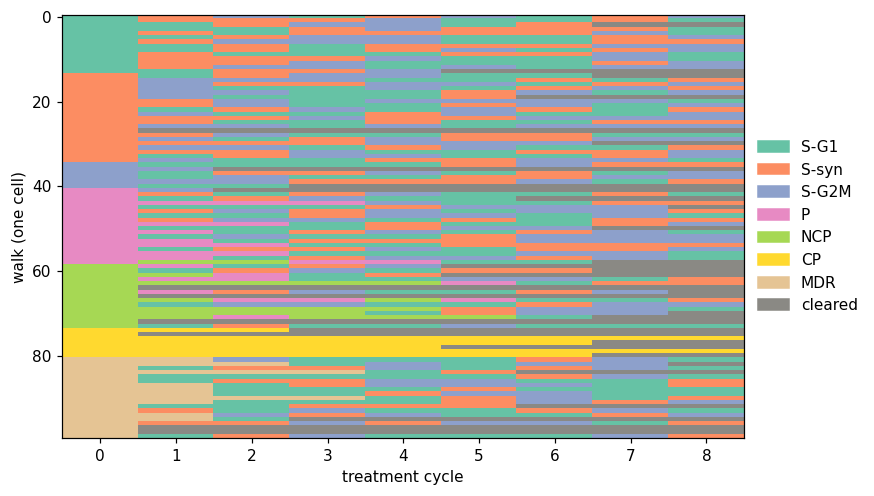

In [153]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [154]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

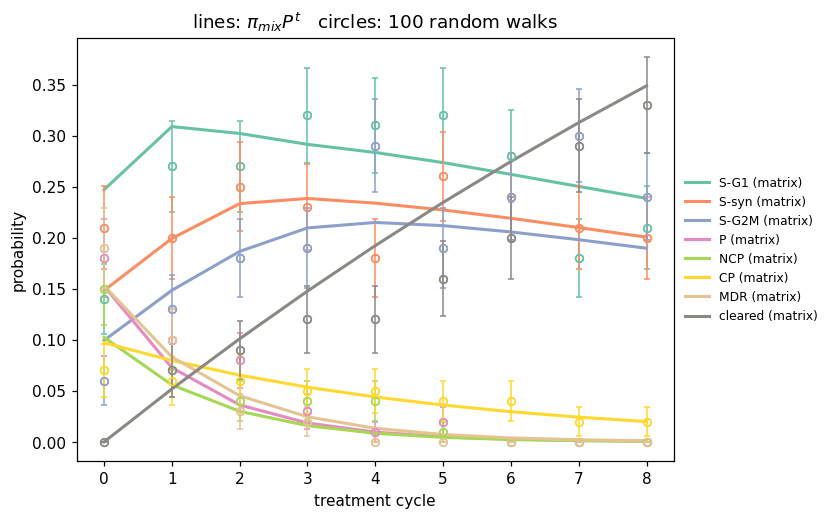

In [155]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

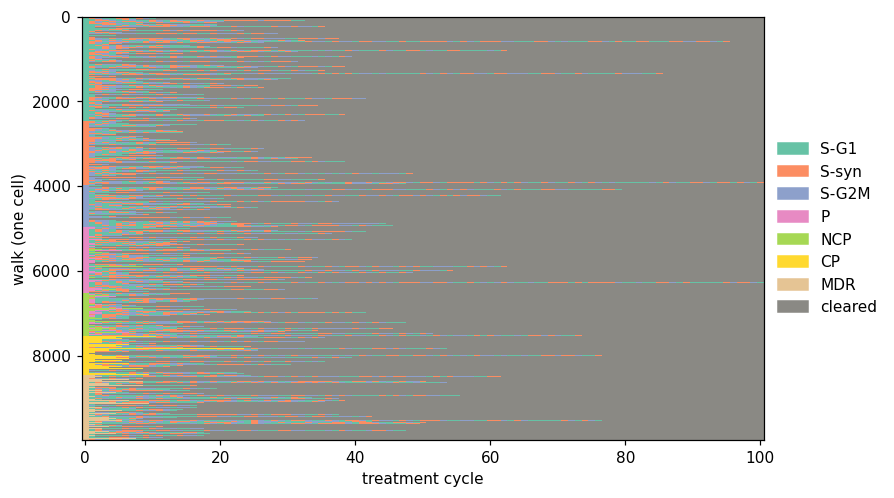

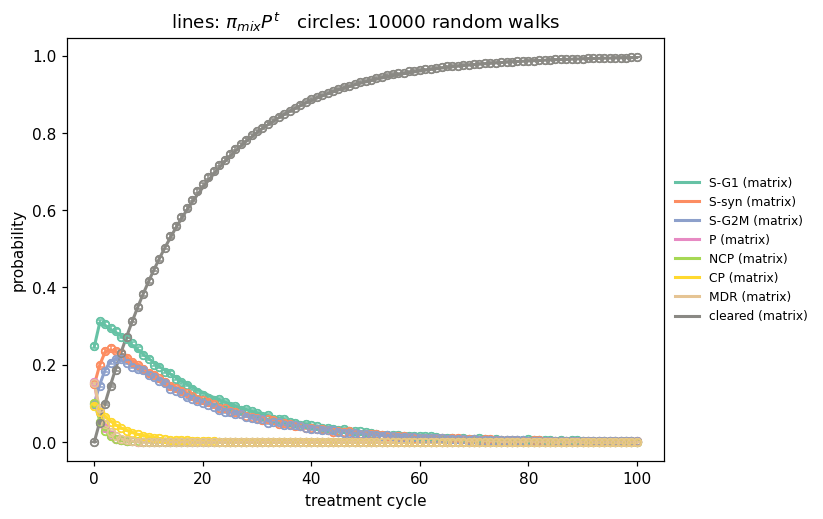

In [228]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

With 10,000, the gaps between the circles and the lines become smaller. This is because the noise that differs from sample to sample that leads to the different proportion outcomes from the ones calculated from the matrix becomes smaller as n increases. As we increase n, gap between the smooth line and the calculated proportion of cells from the individual cell tracking become smaller like the idea expressed in law of large numbers, as essentially proportions are means. 

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [229]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

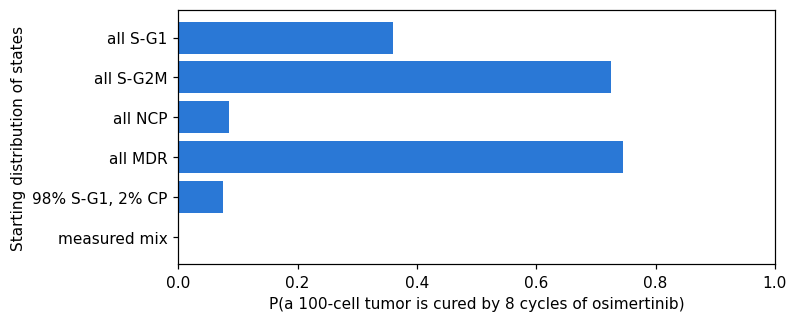

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.360,1.060,0.000
all S-G2M,0.725,0.340,0.000
all NCP,0.085,2.310,0.000
all MDR,0.745,0.305,0.000
"98% S-G1, 2% CP",0.075,2.880,0.635
measured mix,0.000,10.720,0.904


In [230]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

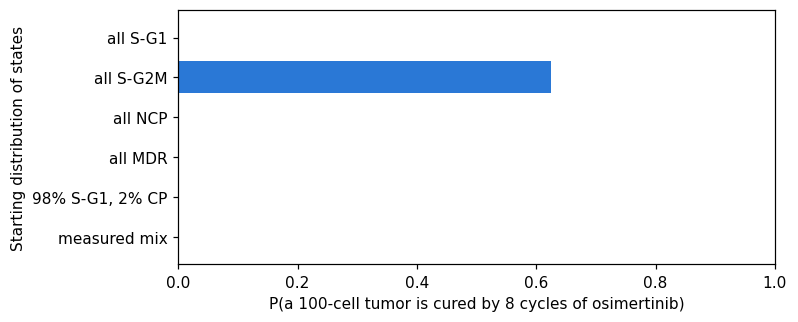

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.000,7.220,0.0
all S-G2M,0.625,0.450,0.0
all NCP,0.000,6.690,0.0
all MDR,0.000,100.000,0.0
"98% S-G1, 2% CP",0.000,7.445,0.0
measured mix,0.000,18.760,0.0


In [231]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc_np, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

When it is with all docetaxel, only tumors where it all starts with S-G2M has a positive probability that the tumor is cured while the other treatment has multiple positive probabilities. If the start state was all S-G2M then there is around a 0.63 probability of a 100 cell turmor being cured by 8 cycles of docetaxel. The mean surviving cells are generally higher than osimertinib for all starting states. 

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [160]:
P = np.array(P_holiday)
P_osi_np = P_hat.to_numpy()
P_doc_np = P_doc.to_numpy()
P_doc_osi = P_doc_np @ P_osi_np 
P_doc_holiday = P_doc_np @ P

In [ ]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors
# I used AI to assist in writing some of the functions

N_CYCLES = 8

def random_walk_1000(treatment):  
    N_WALKS = 1000
    starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
    walks = np.array([random_walk(int(s0), treatment, N_CYCLES, rng) for s0 in starts])
    return walks 

def random_walk_1000_two(treatment): 
    N_WALKS = 1000
    starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
    walks = np.array([random_walk(int(s0), treatment, N_CYCLES//2, rng) for s0 in starts])
    return walks 
# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells
def persister_counter_single(walks):  
    persister_above_three = 0
    persister_states = [OUTCOMES.index(s) for s in ["P", "NCP"]]
    for walk in walks:
        persister_count = 0
        for state in walk:
            if state in persister_states:
                persister_count +=1 
            else: 
                persister_count = 0
            if persister_count >= 3:
                persister_above_three += 1
                break
    return persister_above_three

def persister_counter_double(walks): #Had AI help 
    persister_above_two = 0
    persister_states = [OUTCOMES.index(s) for s in ["P", "NCP"]]
    for walk in walks:
        persister_count = 0
        for state in walk:
            if state in persister_states:
                persister_count +=1 
            else: 
                persister_count = 0
            if persister_count >= 2:
                persister_above_two += 1
                break
    return persister_above_two

# repeat for all tumors
def for_100_tumors(treatment):
    total_persisters = []
    for i in range(100):
        walks_result = random_walk_1000(treatment)
        one_round = persister_counter_single(walks_result)
        turn_percent = one_round/1000
        total_persisters.append(turn_percent)
    return total_persisters


def for_100_tumors_two(treatment):
    total_persisters = []
    for i in range(100):
        walks_result = random_walk_1000_two(treatment)
        one_round = persister_counter_double(walks_result)
        turn_percent = one_round/1000
        total_persisters.append(turn_percent)
    return total_persisters



In [162]:
#for Osimertinib alone 
# report mean +/- SEM for osimertinib

osi_100 = for_100_tumors(P_osi_np)
avg = sum(osi_100)/100
sd = np.std(osi_100,ddof=1)
n_sqrt = np.sqrt(100)
sem = sd/n_sqrt
print(f'The mean for osimertinib is {avg} and the SEM is {sem}')

The mean for osimertinib is 0.11534000000000001 and the SEM is 0.0008885602927991969


In [163]:
# compare to 10% threshold using 95% CI or a hypothesis test
print("95% confidence interval: " , avg - (1.96*sem), avg + (1.96*sem))

95% confidence interval:  0.11359842182611359 0.11708157817388644


It is not 10%, but above it.

<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

In [164]:
def more_than_10(tumor_100):
    counter = 0 
    for i in tumor_100:
        if i > 0.1: 
            counter =counter+ 1 
    percent = counter/100
    return percent 

In [165]:
#Osimertinib alone
osi_100 = for_100_tumors(P_osi_np)
osi_percent = more_than_10(osi_100)
print(osi_percent)
#Doxetaxel alone
doc_100 = for_100_tumors(P_doc_np)
doc_percent = more_than_10(doc_100)
print(doc_percent)
#Alternating OD
doc_osi_100 = for_100_tumors_two(P_doc_osi)
doc_osi_percent = more_than_10(doc_osi_100)
print(doc_osi_percent)

#Doxetaxel with drug holiday
doc_holiday_100 = for_100_tumors_two(P_doc_holiday)
doc_holiday_percent = more_than_10(doc_holiday_100)
print(doc_holiday_percent)

0.92
0.12
0.54
0.03


In [166]:
#increase number of cycles
N_CYCLES = 100 
def random_walk_1000(treatment):
    N_WALKS = 1000
    starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
    walks = np.array([random_walk(int(s0), treatment, N_CYCLES, rng) for s0 in starts])
    return walks 

def random_walk_1000_two(treatment):
    N_WALKS = 1000
    starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
    walks = np.array([random_walk(int(s0), treatment, N_CYCLES//2, rng) for s0 in starts])
    return walks 

In [167]:
#Osimertinib alone
osi_100 = for_100_tumors(P_osi_np)
osi_percent = more_than_10(osi_100)
print(osi_percent)
#Doxetaxel alone
doc_100 = for_100_tumors(P_doc_np)
doc_percent = more_than_10(doc_100)
print(doc_percent)
#Alternating OD
doc_osi_100 = for_100_tumors_two(P_doc_osi)
doc_osi_percent = more_than_10(doc_osi_100)
print(doc_osi_percent)

#Doxetaxel with drug holiday
doc_holiday_100 = for_100_tumors_two(P_doc_holiday)
doc_holiday_percent = more_than_10(doc_holiday_100)
print(doc_holiday_percent)

0.92
0.11
0.53
0.07


Percentage of tumors under the following treatments have more than 10% permanently resistant cells:

- Osimertinib alone: 0.92
- Doxetaxel alone: 0.12
- Alternating OD: 0.54
- Doxetaxel with drug holiday: 0.03


As I increased the number of cycles, the percentage were about the same. 